In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import cv2
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')
# 关闭此 notebook 的 Weights & Biases (wandb) 报告功能
os.environ['WANDB_DISABLED'] = 'true'

In [2]:
image_path = 'football-players-detection/train/images'
labels_path = 'football-players-detection/train/labels'
yaml_path = 'football-players-detection/data.yaml'

In [3]:
# 读取类别名称
with open(yaml_path, 'r') as f:
    import yaml
    data = yaml.safe_load(f)
class_names = data["names"]
class_names

['ball', 'goalkeeper', 'player', 'referee']

In [4]:
image_files = [f for f in os.listdir(image_path) if f.endswith('.jpg')]
random_image_file = np.random.choice(image_files)
random_image_file

np.str_('cd987c_9_9_png.rf.947632e88117f4cb39ce5fe0c4f8b80f.jpg')

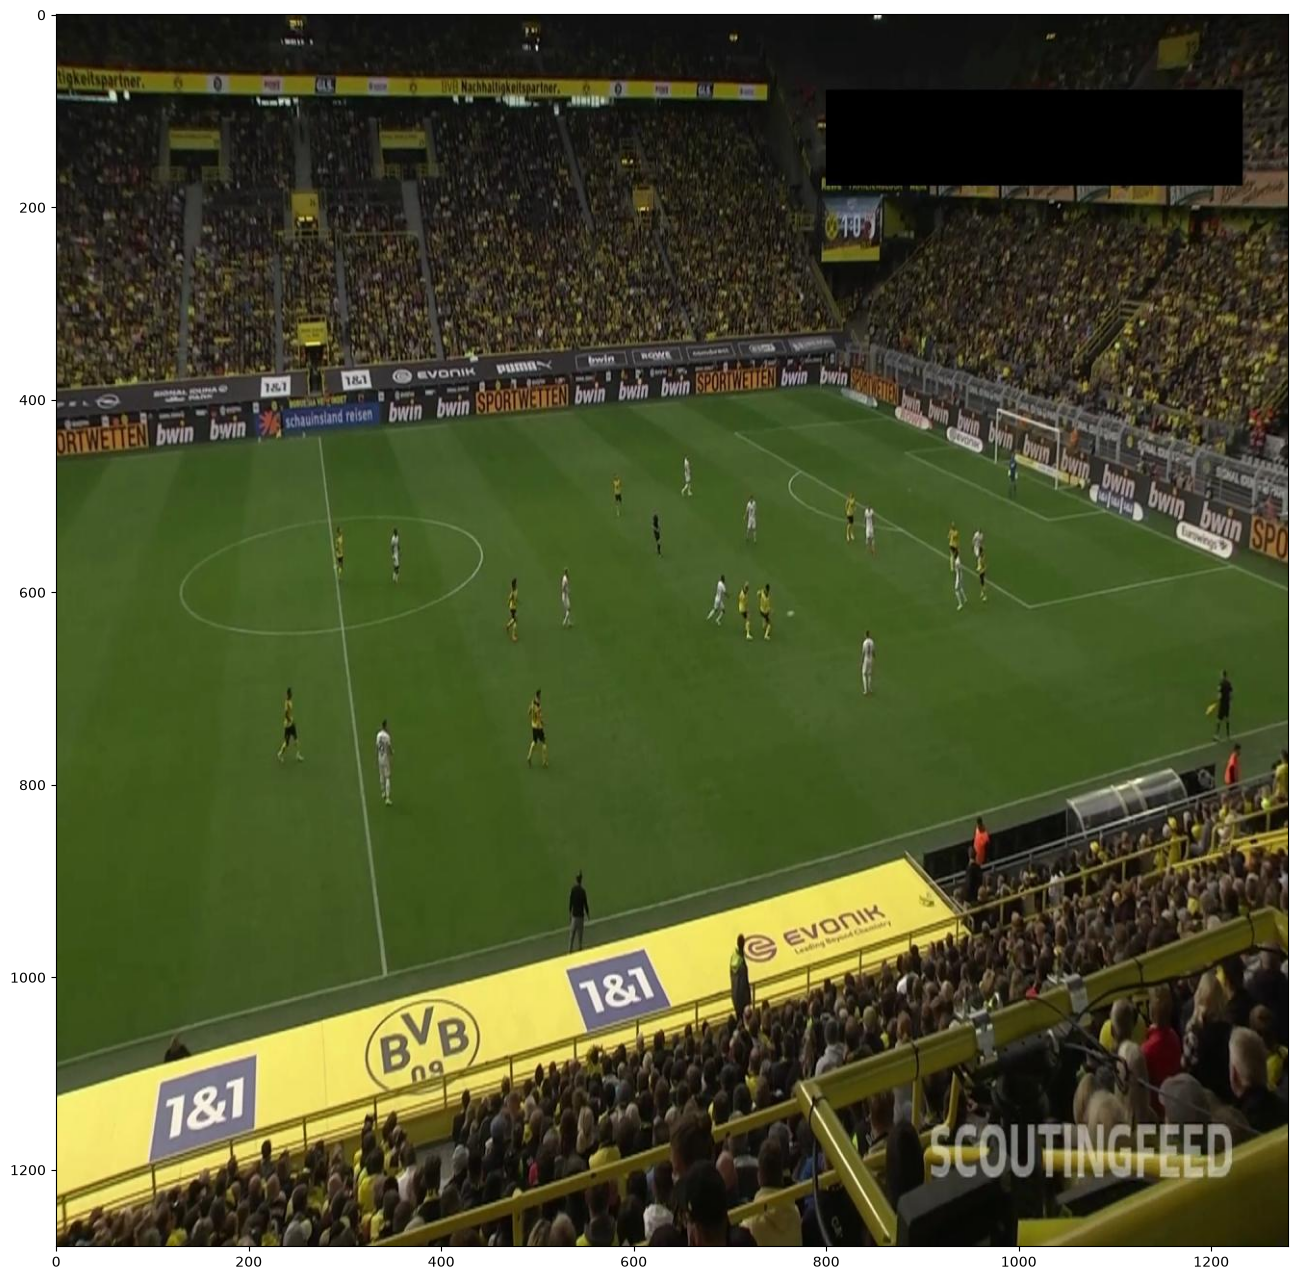

In [5]:
image_path = os.path.join(image_path, random_image_file)
# 读取图片
image = cv2.imread(image_path)
# 将 BGR 转换为 RGB，以便 Matplotlib 正确显示
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
# 进行展示
plt.figure(figsize=(16, 16))
plt.imshow(image)

In [6]:
# 获取对应的标签文件路径
label_filename = os.path.splitext(random_image_file)[0] + ".txt"
label_path = os.path.join(labels_path, label_filename)
# 读取标签文件
with open(label_path, 'r') as f:
    lines = f.readlines()
# 查看内容
lines

['2 0.512109375 0.374609375 0.008984375 0.032421875\n',
 '3 0.487890625 0.421484375 0.008203125 0.037109375\n',
 '2 0.455859375 0.38984375 0.008984375 0.0390625\n',
 '2 0.734375 0.46015625 0.011328125 0.048046875\n',
 '2 0.728515625 0.432421875 0.010546875 0.046484375\n',
 '2 0.6609375 0.419140625 0.009375 0.043359375\n',
 '2 0.7515625 0.453515625 0.011328125 0.046484375\n',
 '2 0.276171875 0.4390625 0.009765625 0.046484375\n',
 '2 0.6453125 0.407421875 0.009375 0.042578125\n',
 '2 0.5640625 0.41015625 0.010546875 0.040625\n',
 '2 0.230078125 0.437109375 0.0078125 0.046484375\n',
 '2 0.37109375 0.483984375 0.0109375 0.052734375\n',
 '2 0.576171875 0.484375 0.0125 0.048046875\n',
 '2 0.415234375 0.47421875 0.009375 0.05\n',
 '2 0.559765625 0.483984375 0.0125 0.04921875\n',
 '2 0.5375 0.475 0.017578125 0.042578125\n',
 '3 0.94453125 0.560546875 0.022265625 0.0578125\n',
 '2 0.659375 0.525390625 0.011328125 0.0546875\n',
 '2 0.190625 0.57578125 0.021875 0.062890625\n',
 '2 0.2671875 0.607

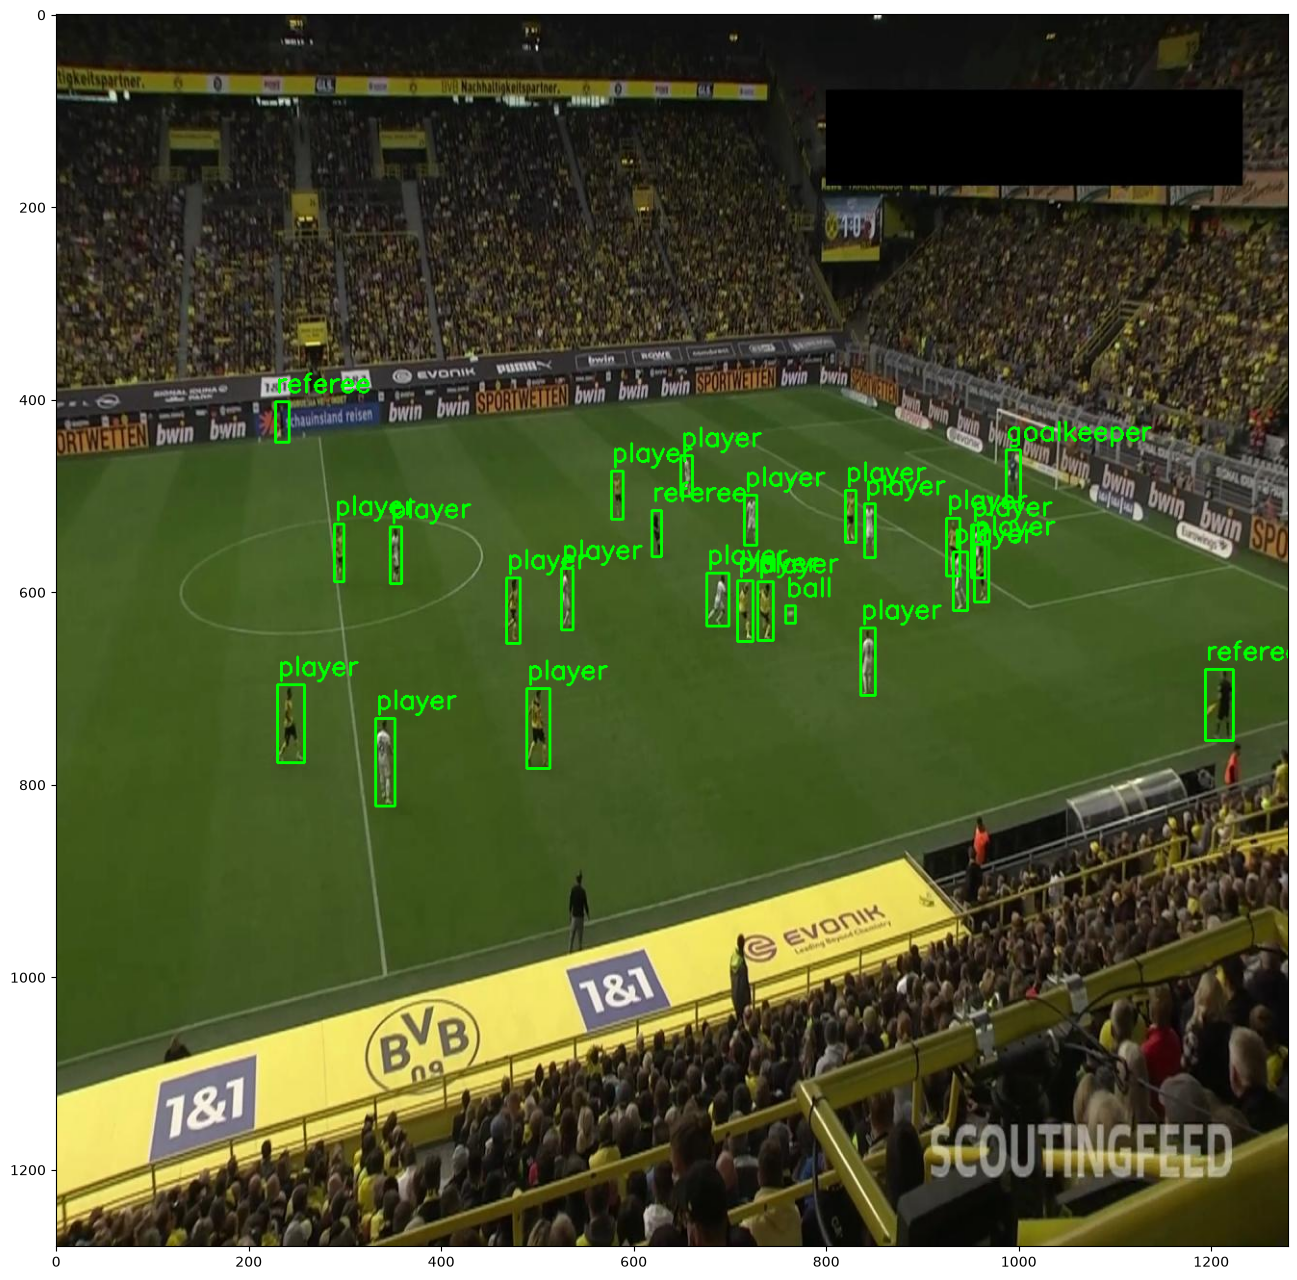

In [7]:
# 解析标签中的每一行
for line in lines:
    # 分割每一行以获取类别 ID 和边界框坐标
    parts = line.strip().split()
    # 将类别 ID 转换为整数
    class_id = int(parts[0])
    # 将边界框的坐标和尺寸转换为浮点数
    cx, cy, w, h = map(float, parts[1:5])

    # 计算边界框的左上角和右下角的坐标
    H, W, _ = image.shape
    x1 = int((cx - w / 2) * W)
    y1 = int((cy - h / 2) * H)
    x2 = int((cx + w / 2) * W)
    y2 = int((cy + h / 2) * H)

    # 获取类别的名称
    label = class_names[class_id]

    # 绘制边界框和类别名称
    color = (0, 255, 0) # 绿色
    thickness = 2
    # 绘制矩形边界框
    cv2.rectangle(image, (x1, y1), (x2, y2), color, thickness)
    # 在边界框上方绘制类别名称
    cv2.putText(image, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, thickness)

# 展示结果
plt.figure(figsize = (16, 16))
plt.imshow(image)

In [8]:
image.shape

(1280, 1280, 3)